In [1]:
import json
import math
import os
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from PIL import Image
from torch import nn
from torch.nn import functional as F

# training.ipynb vive en experimentation/, y el paquete `modules` quedó en la raíz del proyecto
project_root = Path.cwd().resolve().parent
sys.path.append(str(project_root))

from modules.visualizations import visualize_attention, visualize_attention_on_images
from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset, CelebADataset, CIFAR10Dataset
from modules.effective_rank import effective_rank
from modules.cka import linear_cka
import torch
from torch import nn, optim
from modules.experiments import save_experiment, save_checkpoint
import logging
from rich.logging import RichHandler
from tqdm.auto import tqdm

# Apuntar siempre al mlflow.db local (Jupyter ejecuta desde el directorio del notebook)
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Logging con colores vía rich: nivel, timestamp y mensaje coloreados por severidad.
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    datefmt="[%X]",
    handlers=[RichHandler(rich_tracebacks=True, show_path=False)],
    force=True,
)
logger = logging.getLogger("vit_training")

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [3]:
DATASET_NAME = "AwA2"  #@param ["CIFAR10", "CelebA", "AwA2"] {type:"string"}

# Mismo tamaño de entrada (32x32) para las tres, así los checkpoints son comparables entre datasets
# con la misma arquitectura. AwA2 usa el cache local (ver modules.datasets.prepare_awa2_cache).
DATASET_REGISTRY = {
    "CIFAR10": lambda: CIFAR10Dataset(),
    "CelebA": lambda: CelebADataset(),
    "AwA2": lambda: AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2")),
}
dataset = DATASET_REGISTRY[DATASET_NAME]()
trainloader, testloader, classes = dataset.get_loaders(batch_size=128, num_workers=4)
logger.info(f"Dataset {dataset.name} listo: {len(dataset.trainset)} train / {len(dataset.testset)} test, {dataset.n_classes} clases.")

[12:44:06] INFO     Dataset AwA2 listo: 29854 train / 7468 test, 50 clases.

In [4]:
dataset

In [5]:
INDICES = [10, 12, 34, 46, 100]

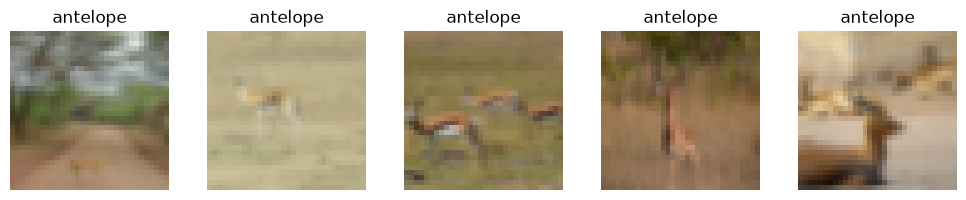

In [6]:
dataset.visualize_sample(indices=INDICES, set="train")

In [7]:
config = {
    "patch_size": 4,  # Input image size: 128x128 -> 32x32 patches
    "hidden_size": 48,
    "num_hidden_layers": 4,
    "num_attention_heads":4,
    "intermediate_size": 4 * 48, # 4 * hidden_size
    "hidden_dropout_prob": 0.0,
    "attention_probs_dropout_prob": 0.0,
    "initializer_range": 0.02,
    "image_size": 32,
    "num_classes": dataset.n_classes,  # 40 atributos binarios de CelebA (multi-label)
    "num_channels": 3,
    "qkv_bias": True,
    "use_faster_attention": False,
}

model = ViTForClassfication(config).to(device)


In [8]:
dataset.get_samples_from_indices(INDICES)[0].shape

torch.Size([5, 3, 32, 32])

In [9]:
random_input = dataset.get_samples_from_indices(INDICES)[0].to(device)
logits, attention_maps = model(random_input, output_attentions=True)

In [10]:
attention_maps[0].shape

torch.Size([5, 4, 65, 65])

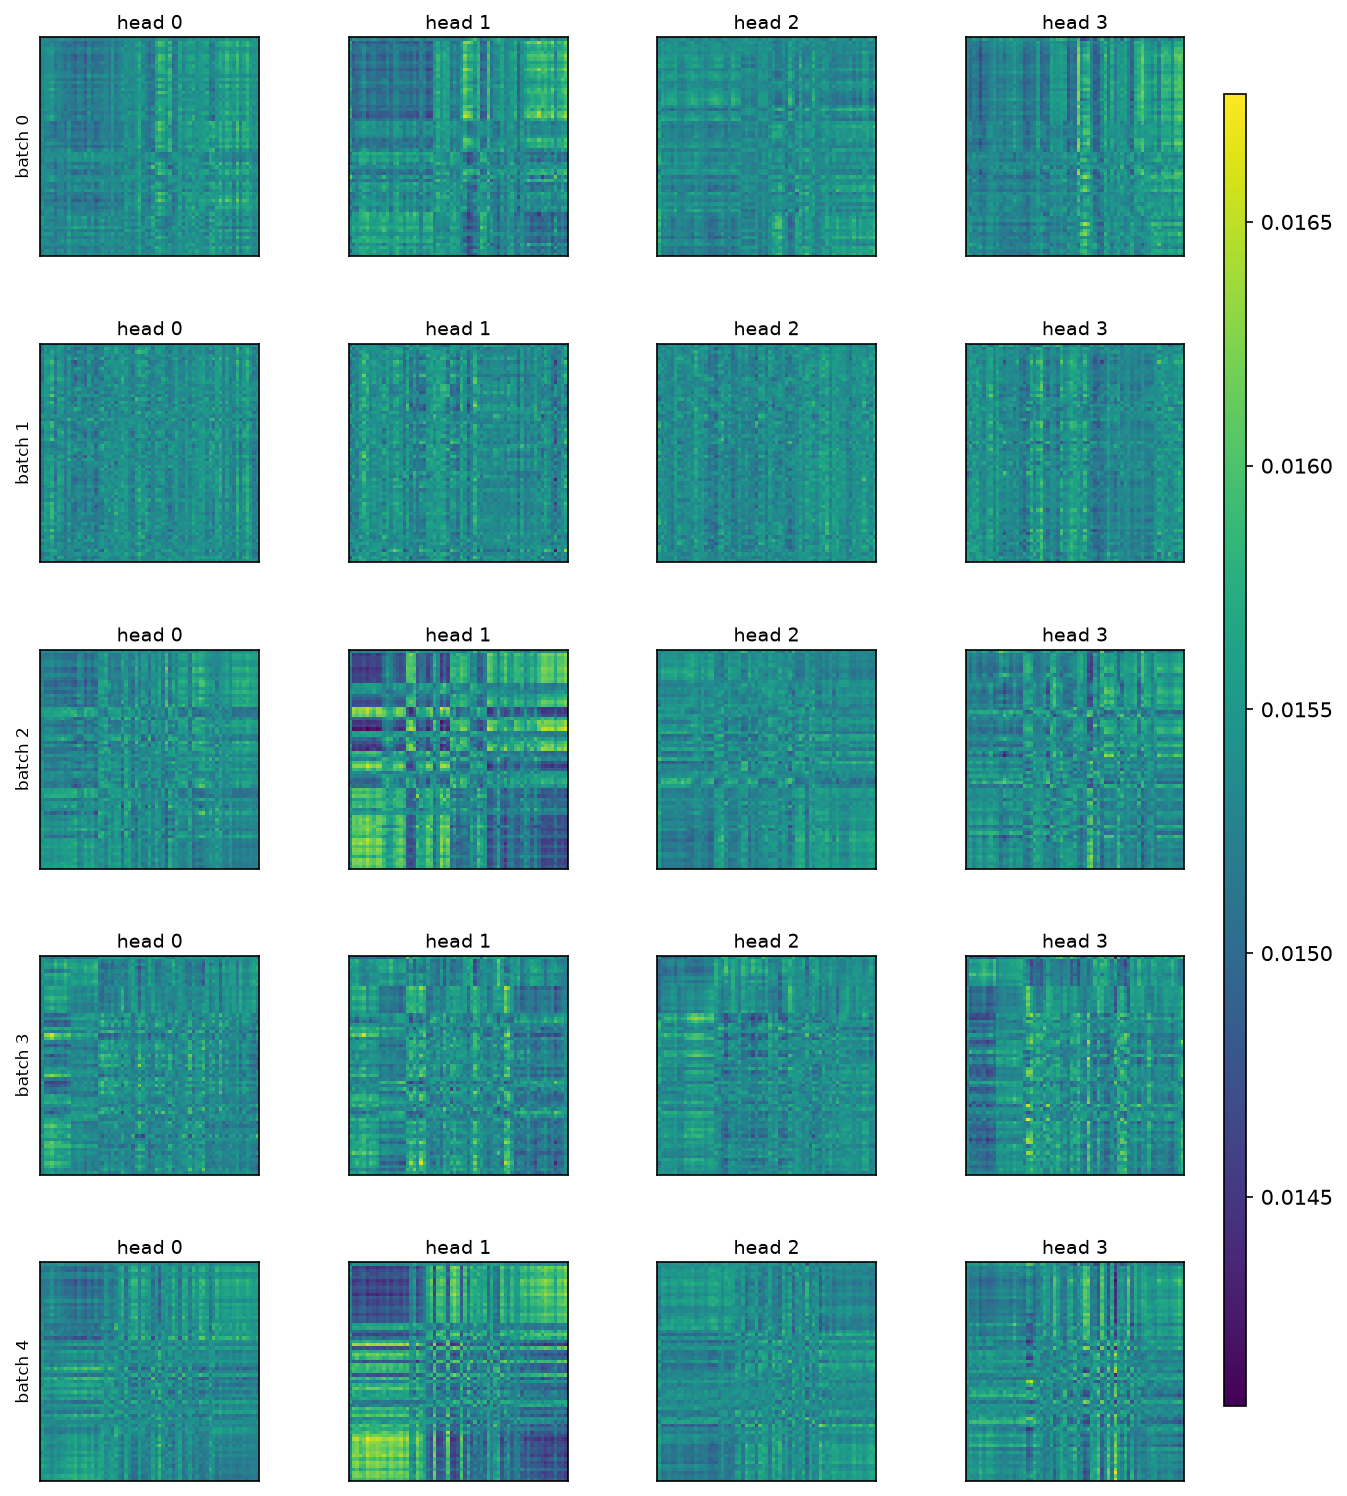

In [11]:
visualize_attention(attention_maps[0])

In [12]:
attention_maps[0].shape

torch.Size([5, 4, 65, 65])

In [13]:
dataset.get_samples_from_indices(INDICES, set="training")[0].shape

torch.Size([5, 3, 32, 32])

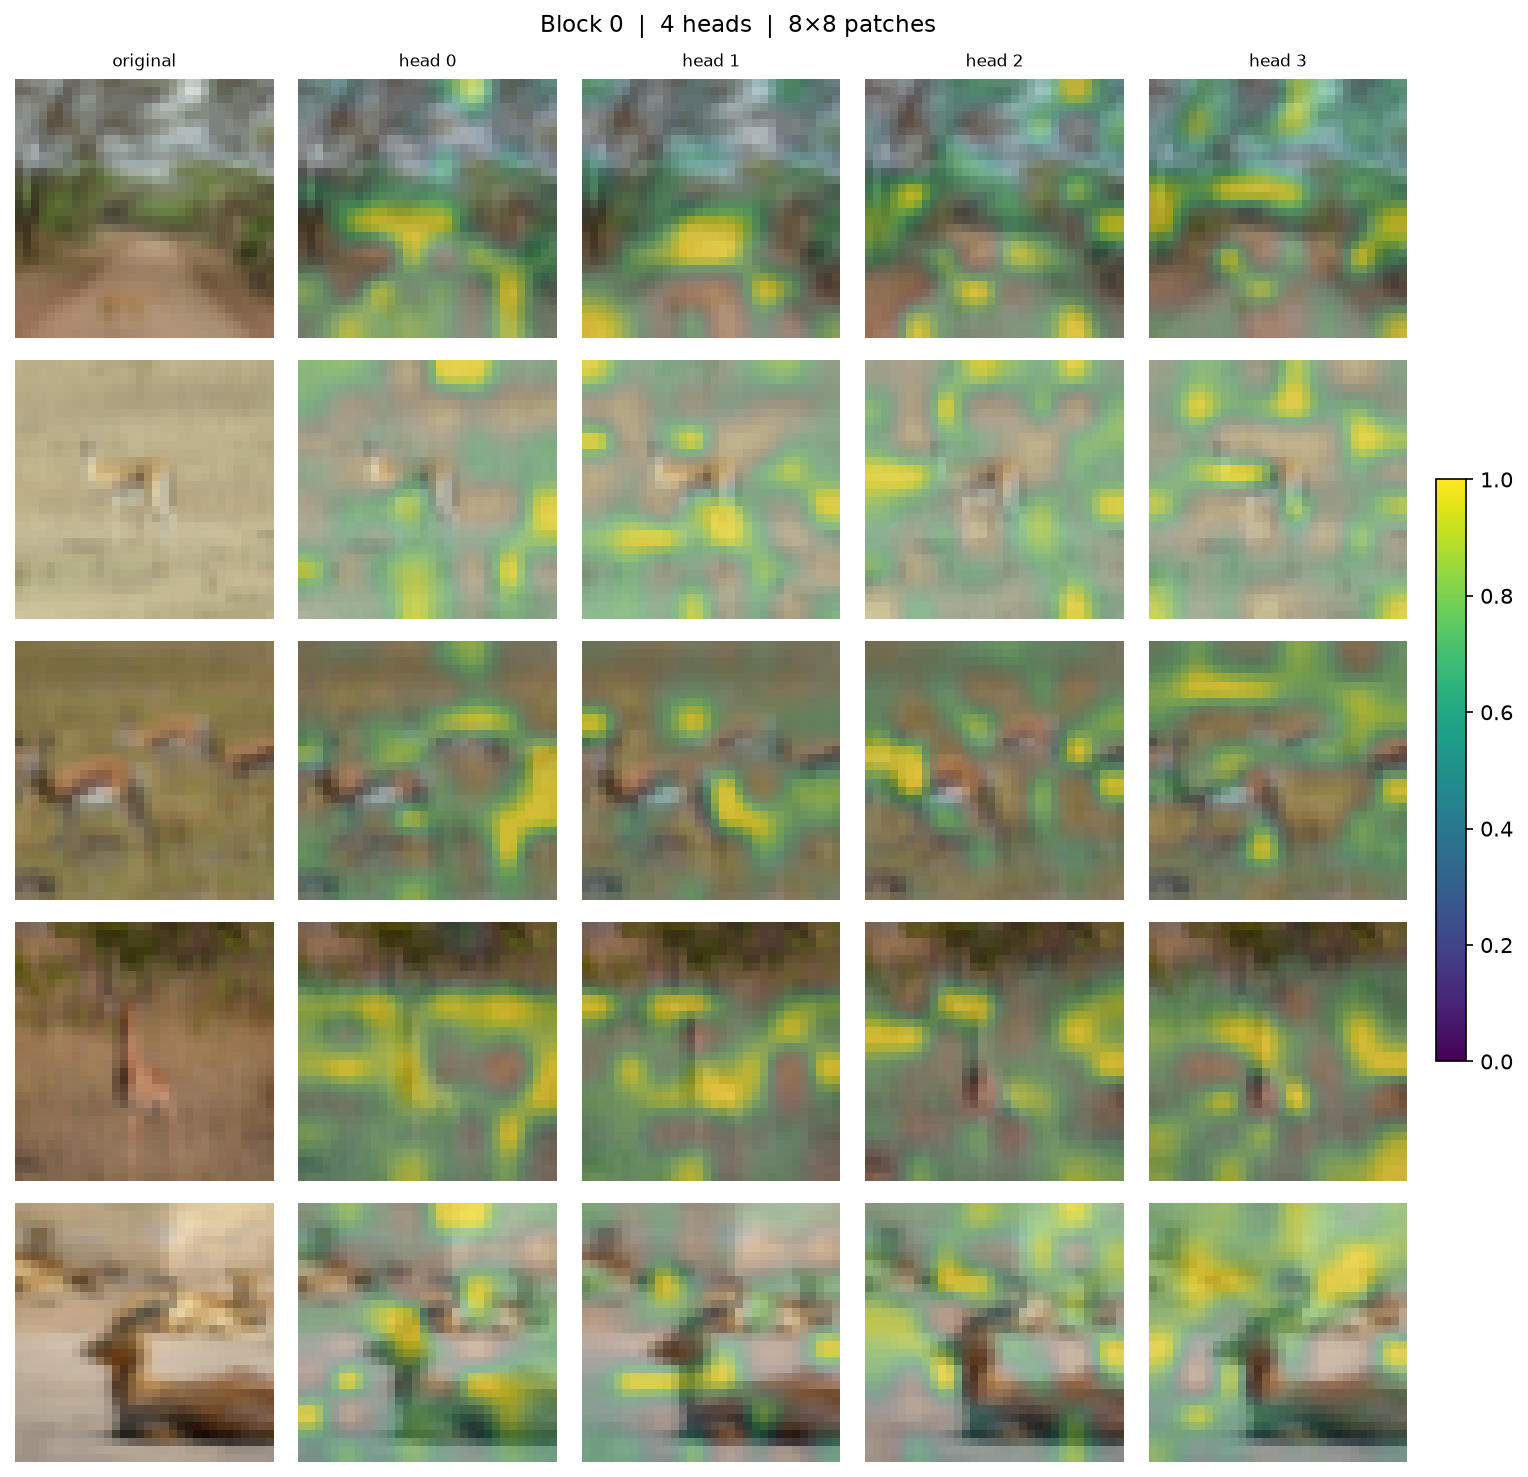

In [14]:
visualize_attention_on_images(attention_maps[0], dataset.get_samples_from_indices(INDICES, set='training')[0])[0]

In [15]:
# Variantes (el nombre del experimento y del run en MLflow salen de aquí):
#   is_constrained=False                      -> "unconstrained"     sin penalización
#   is_constrained=True,  penalize_rank=False -> "constrained"       producto punto entre cabezas (base de comparación)
#   is_constrained=True,  penalize_rank=True  -> "constrained_rank"  producto punto + anti-colapso por cabeza
# Penalización de entropía (lambda_entropy > 0, ver abajo) se suma a cualquiera de las anteriores:
#   is_constrained=False, lambda_entropy>0    -> "entropy_l<λ>"             SOLO localización (cabezas con atención concentrada)
#   is_constrained=True,  lambda_entropy>0    -> "constrained[_rank]_entropy_l<λ>"  coseno entre cabezas + entropía
is_constrained = False #@param {type:"boolean"}
penalize_rank = False #@param {type:"boolean"}   # anti-colapso por cabeza; False -> "constrained"
epochs = 15 #@param {type: "integer"}

# Anti-colapso (modules/loss.py): sobre la SALIDA de cada cabeza del último bloque (token CLS), invariante a escala:
#   - piso de varianza: std por dimensión >= var_floor / sqrt(head_size)  (cabeza constante o muerta)
#   - piso de rango efectivo por cabeza >= rank_target                    (cabeza que usa pocas direcciones)
# penalize_rank = False lo saca de la pérdida, pero las métricas por cabeza se siguen logueando para comparar.
lambda_rank = 1.0 #@param {type: "number"}
rank_on = "head_output"  #@param ["head_output", "attention_map", "qk_weights"] {type:"string"}
rank_target = 3.0 #@param {type: "number"}   # head_output / qk_weights: máx. 12 (head_size); attention_map: máx. 4
var_floor = 0.5 #@param {type: "number"}     # fracción de la std isotrópica 1/sqrt(head_size) exigida (solo head_output)
rank_tokens = "cls"  #@param ["cls", "all"] {type:"string"}
rank_params = ("query", "key")               # solo para rank_on="qk_weights"
rank_floor_active = is_constrained and penalize_rank and lambda_rank > 0
variant = ("constrained_rank" if rank_floor_active else "constrained") if is_constrained else "unconstrained"
# Penalización de entropía de la atención del CLS (último bloque), normalizada H/log(P) en [0, 1]; 0 la desactiva.
# La entropía y el nº efectivo de parches por cabeza (exp(H)) se loguean SIEMPRE en MLflow, también con 0.
lambda_entropy = 0.1 #@param {type: "number"}
if lambda_entropy > 0:
    lam_tag = f"{lambda_entropy:g}".replace(".", "")   # 0.01 -> "001", 0.1 -> "01", 0.5 -> "05" (como constrained_l05)
    variant = (f"{variant}_entropy" if is_constrained else "entropy") + f"_l{lam_tag}"
exp_name = f'vit-{epochs}{"-" + variant if variant != "unconstrained" else ""}-{dataset.name}' #@param {type:"string"}
batch_size = 32 #@param {type: "integer"}
lr = 1e-2  #@param {type: "number"}
save_model_every = 0 #@param {type: "integer"}
lambda_loss = 0.1 #@param {type: "number"}  # peso del coseno entre cabezas (solo si is_constrained)
# Fracción del dataset de entrenamiento a usar (1.0 = 100%). Bajarlo (p.ej. 0.01 = 1%)
# permite correr épocas completas rápido para debuggear el pipeline de evaluación
# sin esperar al dataset completo. No afecta el testloader.
train_fraction = 1.0 #@param {type: "number"}
assert 0 < train_fraction <= 1.0

# Un solo experimento de MLflow por dataset y nº de épocas; cada variante es un run con su nombre
# (`variant`), así las curvas se superponen en el mismo gráfico con una leyenda legible.
# El color de cada run se cambia en la UI (círculo de color junto al nombre del run).
mlflow_experiment = f"vit-{epochs}-epochs-{dataset.name}"
mlflow.set_experiment(mlflow_experiment)
mlflow_note = (
    f"{variant} | dataset={dataset.name}, epochs={epochs}, lr={lr}, batch={batch_size}\n"
    f"- is_constrained={is_constrained}: producto punto (coseno) entre mapas de atención del CLS, "
    f"último bloque, lambda_loss={lambda_loss if is_constrained else 0.0}\n"
    + (f"- anti-colapso ({rank_on}): lambda_rank={lambda_rank}, rank_target={rank_target}, "
       f"var_floor={var_floor}, tokens={rank_tokens}" if rank_floor_active else "- sin término anti-colapso")
    + (f"\n- entropía de la atención del CLS (último bloque, normalizada): lambda_entropy={lambda_entropy}"
       if lambda_entropy > 0 else "\n- sin penalización de entropía")
)
mlflow_tags = {"variant": variant, "dataset": dataset.name, "is_constrained": str(is_constrained),
               "penalize_rank": str(rank_floor_active), "rank_on": rank_on if rank_floor_active else "none",
               "lambda_entropy": str(lambda_entropy)}

config = {
    "patch_size": 4,  # Input image size: 128x128 -> 32x32 patches
    "hidden_size": 48,
    "num_hidden_layers": 4,
    "num_attention_heads": 4,
    "intermediate_size": 4 * 48, # 4 * hidden_size
    "hidden_dropout_prob": 0.0,
    "attention_probs_dropout_prob": 0.0,
    "initializer_range": 0.02,
    "image_size": 32,
    "num_classes": dataset.n_classes,  # 40 atributos binarios de CelebA (multi-label)
    "num_channels": 3,
    "qkv_bias": True,
    "use_faster_attention": False,
}
assert config["hidden_size"] % config["num_attention_heads"] == 0
assert config['intermediate_size'] == 4 * config['hidden_size']
assert config['image_size'] % config['patch_size'] == 0

In [16]:
# Trainer vive en modules/training.py (reutilizado también por
# notebooks/25092026_awa2_probing/train_awa2.ipynb) y las pérdidas de penalización en modules/loss.py.
from modules.training import Trainer
from modules.loss import interpretability_loss, effective_rank_floor_loss

In [17]:
save_model_every_n_epochs = save_model_every
train_sample_size = int(len(dataset.trainset) * train_fraction) if train_fraction < 1.0 else None
logger.info(f"Recargando loaders con batch_size={batch_size}, train_fraction={train_fraction} "
            f"({train_sample_size if train_sample_size is not None else len(dataset.trainset)} muestras)...")
trainloader, testloader, _ = dataset.get_loaders(batch_size=batch_size, num_workers=4,
                                                  train_sample_size=train_sample_size)
model = ViTForClassfication(config)
logger.info(f"Modelo ViT creado: {sum(p.numel() for p in model.parameters()):,} parámetros.")

[12:44:08] INFO     Recargando loaders con batch_size=32, train_fraction=1.0 (29854 muestras)...

           INFO     Modelo ViT creado: 121,058 parámetros.

In [18]:
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
# CelebA es multi-label (40 atributos binarios independientes por imagen), no
# clasificación de una sola clase: BCEWithLogitsLoss trata cada salida del
# clasificador como un sigmoide binario independiente.
loss_fn = nn.BCEWithLogitsLoss() if dataset.multi_label else nn.CrossEntropyLoss()
trainer = Trainer(model, optimizer, loss_fn, exp_name, device=device, config=config,
                  is_constrained=is_constrained, lambda_loss=lambda_loss, batch_size=batch_size, lr=lr,
                  dataset=dataset, log_indices=INDICES, base_dir="experiments",
                  lambda_rank=lambda_rank if rank_floor_active else 0.0,
                  rank_target=rank_target, rank_on=rank_on, rank_params=rank_params,
                  var_floor=var_floor, rank_tokens=rank_tokens, lambda_entropy=lambda_entropy,
                  mlflow_run_name=variant, mlflow_tags=mlflow_tags, mlflow_note=mlflow_note)
trainer.train(trainloader, testloader, epochs, save_model_every_n_epochs=save_model_every_n_epochs)

[12:44:09] INFO     Iniciando entrenamiento 'vit-15-constrained-AwA2': 15 épocas, batch_size=32, lr=0.01,          
                    device=mps

Épocas:   0%|          | 0/15 [00:00<?, ?epoch/s]

Época 1 [train]:   0%|          | 0/933 [00:13<?, ?batch/s]

Época 1 [eval]:   0%|          | 0/234 [00:10<?, ?batch/s]

[12:46:16] INFO     Epoch 1/15 - Train Loss: 3.2639, Train Diversity Loss: 0.2067, Test Loss: 3.0647, Test         
                    Accuracy: 0.1273

Época 2 [train]:   0%|          | 0/933 [00:10<?, ?batch/s]

... (40 outputs left out)

Época 15 [eval]:   0%|          | 0/234 [00:05<?, ?batch/s]

[13:09:48] INFO     Epoch 15/15 - Train Loss: 2.3314, Train Diversity Loss: 0.0728, Test Loss: 2.4181, Test        
                    Accuracy: 0.2879

           INFO     Entrenamiento finalizado. Modelo y métricas guardados para 'vit-15-constrained-AwA2'.

{'cls_loss': 2.6737118823151302,
 'interpretability_loss': 0.11728195354947422,
 'attn_erank': 3.796766757965088,
 'rank_loss': 0.1235784510962474,
 'total_loss': 2.418068831675073,
 'accuracy': 0.2878950187466524}

mlflow.end_run()

In [ ]:
mlflow.end_run()

In [20]:
current_date = datetime.now().strftime("%Y-%m-%d-%H-%M-%S")
model_path = f"vit_final_{dataset.name}_{current_date}_{variant}.pt"
torch.save(model.state_dict(), model_path)
logger.info(f"Modelo final guardado en {model_path}")

           INFO     Modelo final guardado en vit_final_AwA2_2026-10-12-13-09-48_constrained.pt